#### **B**idirectional **E**ncoder **R**epresentation for **T**ransformers
A masked-language BERT over genes (cells as *sentences*; genes as *tokens*)

In [1]:
import os             # operating system interfaces
import re             # regular expressions for pattern matching in strings (e.g., cleaning gene names)
import numpy as np    # numerical computing
import pandas as pd   # dataframes

import scanpy as sc    # the main toolkit for single-cell RNA-seq data (normalization, clustering, etc.)
import anndata as ad   # the data structure used by Scanpy (cells × genes matrix + metadata)

import torch  # the PyTorch deep learning library
import gc     # Python’s garbage collector; used to manually free GPU memory sometimes
from torch.utils.data import Dataset, DataLoader # handle batching and iteration over data during training
from torch.utils.data import random_split
from dataclasses import dataclass                # Used to create lightweight classes for storing data (e.g., configs, parameters) without boilerplate code

import random  # for random number generation
import json    # for reading/writing JSON files (e.g., model configs, vocabularies)

import mygene as mg 
import gseapy as gp


# .. using Hugging Face Transformers, specifically BERT (Bidirectional Encoder Representations from Transformers).
# BertConfig: defines model architecture and hyperparameters.
# BertForMaskedLM: BERT model for masked language modeling to be repurposed for gene expression reconstruction.
# Trainer, TrainingArguments: high-level tools to handle training loops, logging, checkpoints, etc.

from transformers import BertConfig, BertForMaskedLM, Trainer, TrainingArguments

import scipy.sparse as sp         # efficient operations on large sparse matrices (like gene counts).
import math                       # basic math functions (sqrt, log, etc.) when you don’t need NumPy. 
import matplotlib.pyplot as plt   # Plotting 

from numpy.linalg import norm
import umap
from scipy.sparse import vstack 

In [2]:
# adjust you own path
commonpath = "/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/"

In [8]:
# this auxiliary function checks whether an AnnData object is raw counts or normalized/log-transformed
def check_raw(adata, name="adata"):
    X = adata.X

    # extract only non-zero entries
    if sp.issparse(X):
        vals = X.data
    else:
        arr = np.asarray(X)
        vals = arr[arr > 0]

    print(f"--- {name} ---")
    print("Number of non-zero entries:", vals.size)

    if vals.size == 0:
        print("All zeros → not raw.")
        return

    # integer-ness check
    int_fraction = np.mean(np.isclose(vals, np.round(vals), atol=1e-8))
    print("Fraction of approx-integer entries:", int_fraction)

    print("Min nonzero:", vals.min())
    print("Max:", vals.max())

    if int_fraction > 0.999:
        print("→ Very likely RAW counts.")
        print("")
    else:
        print("→ Normalized or log-transformed.")
        print("")

>**Datasets**

We **already** have: (import below)
- A_dev_aln and A_cancer_aln (same 15,376 genes, same order)
- Dev labels in A_dev_aln.obs['dev_state_pancreas'] (e.g., acinar_or_tip, ductal)
- Cancer stages in A_cancer_aln.obs['condition_norm'] (e.g., N1, N2, K1, K1.5, …, K6)

In [ ]:
# Paths (must match your previous save locations)
in_cancer = os.path.join(commonpath, "pdac/A_cancer_aligned.h5ad")  
in_dev    = os.path.join(commonpath, "development/A_dev_aligned.h5ad")     

A_cancer_aln = sc.read_h5ad(in_cancer)
A_dev_aln    = sc.read_h5ad(in_dev)

# .. cancer dataset
print(f"\n[cancer] {A_cancer_aln.n_obs:,} cells × {A_cancer_aln.n_vars:,} genes")
print(f"  obs: {list(A_cancer_aln.obs.columns)}")
print(f"  obsm: {list(A_cancer_aln.obsm.keys())}")
print(f"  layers: {list(A_cancer_aln.layers.keys()) if A_cancer_aln.layers else '—'}")

# .. developmental dataset
print(f"\n[dev] {A_dev_aln.n_obs:,} cells × {A_dev_aln.n_vars:,} genes")
print(f"  obs: {list(A_dev_aln.obs.columns)}")
print(f"  obsm: {list(A_dev_aln.obsm.keys())}")
print(f"  layers: {list(A_dev_aln.layers.keys()) if A_dev_aln.layers else '—'}")


[cancer] 28,131 cells × 15,376 genes
  obs: ['batch', 'condition', 'cluster', 'epi_score', 'cancer_state', 'condition_collapsed']
  obsm: []
  layers: —

[dev] 34,760 cells × 15,376 genes
  obs: ['cell_id', 'keep', 'day', 'embryo_id', 'experimental_batch', 'cell_id_base', 'major_trajectory', 'celltype_update', 'endo_category', 'day_meta', 'dev_state_pancreas', 'dev_state_union', 'dev_day', 'source_file', 'dev_tier']
  obsm: []
  layers: —


In [10]:
check_raw(A_dev_aln, "development")
check_raw(A_cancer_aln, "cancer")

--- development ---
Number of non-zero entries: 57139701
Fraction of approx-integer entries: 1.0
Min nonzero: 1.0
Max: 1803.0
→ Very likely RAW counts.

--- cancer ---
Number of non-zero entries: 87098503
Fraction of approx-integer entries: 1.0
Min nonzero: 1.0
Max: 46624.0
→ Very likely RAW counts.



`Pancreas cells`

| Cell Type     | Function                                           | Location               |
|---------------|----------------------------------------------------|------------------------|
| Acinar Cells  | Produce digestive enzymes                          | Acini                  |
| Ductal Cells  | Transport enzymes and bicarbonate                 | Pancreatic ducts       |
| Alpha Cells   | Produce glucagon                                   | Islets of Langerhans   |
| Beta Cells    | Produce insulin                                    | Islets of Langerhans   |
| Delta Cells   | Produce somatostatin                              | Islets of Langerhans   |
| PP Cells      | Produce pancreatic polypeptide                     | Islets of Langerhans   |
| Stellate Cells| Regulate extracellular matrix and fibrosis response| Pancreatic stroma      |


#### *pre* CORPUS

> **Next steps:**  Raw counts from `.X` → convert to dense int → mask → tokenize → train.

In [11]:
# A_dev_aln and A_cancer_aln already have RAW counts in .X
# We keep them as is for the MLM.

def to_dense_int(X):
    """
    Ensure we have a dense int32 array of non-negative counts.
    Use this as the backing array for the MLM corpus.
    """
    if sp.issparse(X):
        X = X.toarray()
    X = np.asarray(X)
    
    # safety checks
    if (X < 0).any():
        raise ValueError("Found negative values in count matrix.")
    
    # round tiny numerical noise (if any) and cast to int
    X = np.rint(X).astype(np.int32)
    return X

# Development and cancer count matrices for the MLM
X_dev_counts    = to_dense_int(A_dev_aln.X)
X_cancer_counts = to_dense_int(A_cancer_aln.X)

print("Dev counts shape   :", X_dev_counts.shape)
print("Cancer counts shape:", X_cancer_counts.shape)


Dev counts shape   : (34760, 15376)
Cancer counts shape: (28131, 15376)


#### CORPUS BUILDING

- We turn each cell into a short “sentence” of its top-K genes (by expression rank). 
- Ordering is by descending expression normalizing by nonzero mean (Geneformer and Zebraformer's approach)


#### **tokenization**

In [12]:
# 0) configuration
# tokens per cell (I used 512 in Zebraformer, which is a larger dataset, but 128 is ok for small ones)
TOP_K = 128 
# The padding token, used to fill sequences to a uniform length for batch processing. This token is ignored during model training and prediction.
PAD_ID = 0 
# The classification token, which is typically added at the beginning of the input sequence. 
# It is used for tasks like classification, where the final output from this token is often used as the representation for the entire sequence.
CLS_ID = 1

# The separator token is used to differentiate between different segments in a sequence. 
# For example, in tasks that involve sentence pairs, this token separates the two sentences.
SEP_ID = 2
# The masking token, used during training to indicate which tokens should be masked (hidden) for tasks like masked language modeling. The model learns to predict these masked tokens based on context.
MASK_ID = 3
# The rest of ids [4..] will be genes (1:1 with your var_names order)

# shared gene vocabulary 
genes = A_dev_aln.var_names.to_numpy()   # already aligned to A_cancer_aln
assert (genes == A_cancer_aln.var_names.to_numpy()).all(), "Mismatch between gene identifiers"

gene2id = {g: i+4 for i, g in enumerate(genes)}   # shift by 4 for special tokens
vocab_size = 4 + len(genes)

>**Normalization**

Per-cell library-size normalization

In [13]:
def library_normalize_per_cell(X, target_sum=1e4, dtype=np.float32):
    """
    Per-cell library-size normalization.

    X: array-like, shape (n_cells, n_genes), raw integer counts.
    target_sum: each cell is scaled so its total counts = target_sum.
    Returns:
        X_norm: normalized matrix, float32
        lib_sizes: original library sizes per cell (before scaling)
    """
    X = np.asarray(X, dtype=np.float32)
    lib_sizes = X.sum(axis=1, keepdims=True)  # (n_cells, 1)

    # avoid division by zero for weird empty cells
    zero_lib = (lib_sizes == 0)
    if np.any(zero_lib):
        print(f"[WARN] {zero_lib.sum()} cells have zero total counts; "
              "they will become all zeros after normalization.")
        lib_sizes[zero_lib] = 1.0

    X_norm = X / lib_sizes * float(target_sum)
    return X_norm.astype(dtype), lib_sizes.squeeze(-1)

per-gene “developmental scale”

In [16]:
# non-zero median per gene (developmental baseline)

def nonzero_median_per_gene_dense(X):
    """
    Compute per-gene median over *non-zero* entries across cells.

    X: array-like, shape (n_cells, n_genes), typically normalized counts.
    Returns:
        medians: shape (n_genes,), float32
    """
    X = np.asarray(X, dtype=np.float32)
    n_cells, n_genes = X.shape
    medians = np.zeros(n_genes, dtype=np.float32)

    # We use a simple loop because n_genes is usually manageable (this can be vectorized later).
    for j in range(n_genes):
        col = X[:, j]
        nz = col[col > 0]
        if nz.size > 0:
            medians[j] = np.median(nz)
        else:
            medians[j] = 0.0  # never expressed in dev; handle later
    return medians

> Apply to your dev + cancer matrices

In [14]:
# Library-size normalization (each dataset independently)
# Every cell ends up with total “counts” ≈ 10,000. 
# This is standard CPM-like normalization; it removes trivial differences due to “this cell had 2× more UMIs captured”.
X_dev_norm, dev_lib_sizes = library_normalize_per_cell(X_dev_counts, target_sum=1e4)
X_cancer_norm, cancer_lib_sizes = library_normalize_per_cell(X_cancer_counts, target_sum=1e4)

print("Dev norm shape:", X_dev_norm.shape)
print("Cancer norm shape:", X_cancer_norm.shape)

Dev norm shape: (34760, 15376)
Cancer norm shape: (28131, 15376)


In [17]:
# Developmental baseline: per-gene non-zero median in **normalized** dev data
# Typical expression level of gene g when it’s on somewhere in development, measured in dev-normalized units.
dev_baseline = nonzero_median_per_gene_dense(X_dev_norm)
print("Dev baseline summary:")
print("  #genes:", dev_baseline.size)
print("  #genes with baseline == 0:", np.sum(dev_baseline == 0))


Dev baseline summary:
  #genes: 15376
  #genes with baseline == 0: 76


In [18]:
# Compute dev-relative scores (ratio to dev baseline)
# Avoid division by 0 by using a 'safe' baseline and tracking zero-baseline genes.

zero_baseline = (dev_baseline == 0)
if np.any(zero_baseline):
    print(f"[INFO] {zero_baseline.sum()} genes have dev baseline == 0 "
          "(never detected in developmental data).")

dev_baseline_safe = dev_baseline.copy()
dev_baseline_safe[zero_baseline] = 1.0  # temporary placeholder to avoid /0

# dev-relative ratios: how much a cell expresses gene j compared to the dev median of gene j
dev_rel    = X_dev_norm    / dev_baseline_safe[None, :]
cancer_rel = X_cancer_norm / dev_baseline_safe[None, :]

# For genes never seen in development, set ratio to 0 and keep a mask.
dev_rel[:, zero_baseline] = 0.0
cancer_rel[:, zero_baseline] = 0.0

# dev_rel and cancer_rel now have the same shape as the original matrices.
print("Dev-relative shapes:", dev_rel.shape, cancer_rel.shape)

[INFO] 76 genes have dev baseline == 0 (never detected in developmental data).
Dev-relative shapes: (34760, 15376) (28131, 15376)


If cancer_rel[g,c] ≈ 1 → gene g in that cancer cell c is at about the typical developmental “on” level.

If ≫ 1 → it’s above typical dev ON level.\
If ≪ 1 but > 0 → it’s detectable but below typical dev ON level.

- For genes never detected in dev (baseline 0):
You set both dev_rel and cancer_rel to 0.
You keep a mask (dev_baseline_zero) so you know these are “off-manifold” genes.

- So the shared coordinate system for dev and cancer is:
**“Expression in this *cell*, divided by the typical developmental ON-expression for that gene.”**


**Building new Ann objects**

In [19]:
# AnnData for MLM input (dev)
A_dev_mlm = sc.AnnData(
    X    = dev_rel.astype(np.float32),   # MAIN matrix = dev-relative scores
    obs  = A_dev_aln.obs.copy(),
    var  = A_dev_aln.var.copy()
)

# store developmental baseline information in .var
A_dev_mlm.var["dev_baseline"]       = dev_baseline.astype(np.float32)
A_dev_mlm.var["dev_baseline_zero"]  = zero_baseline

# AnnData for MLM input (cancer)
A_cancer_mlm = sc.AnnData(
    X   = cancer_rel.astype(np.float32),   # MAIN matrix = dev-relative scores
    obs = A_cancer_aln.obs.copy(),
    var = A_cancer_aln.var.copy()
)

# same baseline annotations (same gene order by construction)
A_cancer_mlm.var["dev_baseline"]      = dev_baseline.astype(np.float32)
A_cancer_mlm.var["dev_baseline_zero"] = zero_baseline

In [20]:
print(A_dev_mlm)
print(A_cancer_mlm)

AnnData object with n_obs × n_vars = 34760 × 15376
    obs: 'cell_id', 'keep', 'day', 'embryo_id', 'experimental_batch', 'cell_id_base', 'major_trajectory', 'celltype_update', 'endo_category', 'day_meta', 'dev_state_pancreas', 'dev_state_union', 'dev_day', 'source_file', 'dev_tier'
    var: 'symbol', 'dev_baseline', 'dev_baseline_zero'
AnnData object with n_obs × n_vars = 28131 × 15376
    obs: 'batch', 'condition', 'cluster', 'epi_score', 'cancer_state', 'condition_collapsed'
    var: 'symbol_orig', 'symbol', 'dev_baseline', 'dev_baseline_zero'


In [27]:
# one global mask, same gene order for dev and cancer
baseline_zero_mask = A_dev_mlm.var["dev_baseline_zero"].values  # shape (n_genes,)

In [33]:
# After creating A_dev_mlm and A_cancer_mlm with dev_rel / cancer_rel in .X:
# NOTE: A_dev_mlm.X[g] ≈ (normalized_count_g) / (dev_median_g)

# log1p of the ratio (so dynamic range isn’t insane),
# mask genes with no dev baseline (dev_baseline_zero),
# handle the “all zeros” case cleanly.

def cell_to_tokens_dev_relative(X_row, baseline_zero_mask, top_k=TOP_K):
    """
    X_row: 1D row from A_dev_mlm.X or A_cancer_mlm.X.
           These are dev-relative ratios:
               X_row[g] ≈ (normalized_count_g) / (dev_median_g)

    We:
      - log1p-transform the ratios,
      - zero out genes with no developmental baseline,
      - pick top_k genes by this score,
      - build [CLS] + genes + [SEP] and pad.
    """
    # to dense vector
    if hasattr(X_row, "toarray"):
        X_row = X_row.toarray().ravel()
    else:
        X_row = np.asarray(X_row).ravel().astype(np.float32)

    # dev-relative scores: log1p of ratio
    eps = 1e-6
    scores = np.log1p(np.maximum(X_row, 0.0) + eps)

    # clean numeric junk
    scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

    # suppress genes that never had a dev baseline
    if baseline_zero_mask is not None:
        scores[baseline_zero_mask] = 0.0

    # if everything is zero, just output CLS + SEP + PAD...
    if np.all(scores == 0):
        token_ids = [CLS_ID, SEP_ID] + [PAD_ID] * top_k
        return np.array(token_ids, dtype=np.int64)

    # top-k selection
    n_genes = scores.shape[0]
    k = min(top_k, n_genes)

    idx_k = np.argpartition(-scores, k - 1)[:k]
    idx_sorted = idx_k[np.argsort(-scores[idx_k], kind="stable")]

    # gene index → token id (offset by 4)
    token_ids = [CLS_ID] + (idx_sorted[:top_k] + 4).tolist() + [SEP_ID]

    # pad to fixed length
    max_len = top_k + 2
    if len(token_ids) < max_len:
        token_ids += [PAD_ID] * (max_len - len(token_ids))

    return np.array(token_ids, dtype=np.int64)


**Vectorizing for an AnnData**

Returns:
- tokens: shape (n_cells, TOP_K+2).
- attn: same shape, 1 where not PAD, 0 where PAD. This is your attention mask for BERT.

Note : If you later increase sequence length (e.g., adding domain tokens and keeping [SEP]), change the second dimension accordingly.

> Here are the top-k genes that are most strongly over-expressed relative to their typical developmental level

In [35]:
def adata_to_token_matrix(A, baseline_zero_mask, top_k=TOP_K):
    n_cells = A.n_obs
    seq_len = top_k + 2  # CLS + top_k genes + SEP
    tokens = np.empty((n_cells, seq_len), dtype=np.int64)

    for i in range(n_cells):
        tokens[i] = cell_to_tokens_dev_relative(
            A.X[i],
            baseline_zero_mask=baseline_zero_mask,
            top_k=top_k,
        )

    attn = (tokens != PAD_ID).astype(np.int64)
    return tokens, attn

**Build dev/cancer corpora**

In [36]:
dev_tokens, dev_attn = adata_to_token_matrix(A_dev_mlm,   baseline_zero_mask, top_k=TOP_K)
can_tokens, can_attn = adata_to_token_matrix(A_cancer_mlm, baseline_zero_mask, top_k=TOP_K)


In [37]:
print(A_dev_mlm.X.min(), A_dev_mlm.X.max())
print(A_cancer_mlm.X.min(), A_cancer_mlm.X.max())

print(dev_tokens.shape, can_tokens.shape)
print(dev_attn.shape,   can_attn.shape)

print(dev_tokens[0][:20])
print(dev_attn[0][:20])

0.0 242.44366
0.0 1748.7064
(34760, 130) (28131, 130)
(34760, 130) (28131, 130)
[    1 12352  1954  3803  8902  8546 10011  3516   785  2227  8005  1427
  3482  1676 12868  9750  5874  6340  6537 10349]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


**Should you remove padding?**
No. 

Padding is *mandatory* for:
- batching,
- consistent sequence length,
- GPU parallelization,
- the HuggingFace Trainer,
- BERT architecture itself.

The fact that padding didn’t activate doesn’t mean you can remove it — it means TOP_K is comfortably lower than the number of available genes in each cell.

If you ever lower TOP_K or work with a sparser dataset, padding will kick in immediately.

**(Optional) Domain tokens**

- extend the vocabulary with domain tags ([DEV], [CANCER]).
- This helps the model learn domain-specific quirks while sharing most parameters.

- Why: a [DEV] or [CANCER] token tells one shared BERT “which dialect” a sentence comes from, while still sharing most parameters. 
    - It improves shared-space training and lets the model learn domain-specific quirks without splitting models.
- What changes:
    - Add two new tokens to the vocabulary: DEV_DOM_ID, CANCER_DOM_ID → vocab_size += 2.

-Sequence layout becomes:
[DOM] [CLS] <K gene tokens> [SEP]

Sequence length increases by +1 (keep both [CLS] and [SEP])

In [38]:
# Add domain tokens to the vocabulary
DEV_DOM_ID    = vocab_size
CANCER_DOM_ID = vocab_size + 1
vocab_size   += 2

def prepend_domain_token(tokens: np.ndarray, dom_id: int, PAD_ID: int) -> tuple[np.ndarray, np.ndarray]:
    """
    Input tokens are [CLS] + K genes + [SEP] (shape: N x (K+2)).
    Output tokens are [DOM] + [CLS] + K genes + [SEP] (shape: N x (K+3)).
    Attention mask is 1 for non-PAD positions.
    """
    N, L = tokens.shape
    out = np.full((N, L + 1), PAD_ID, dtype=tokens.dtype)
    out[:, 0]  = dom_id
    out[:, 1:] = tokens
    attn = (out != PAD_ID).astype(np.int64)
    return out, attn

dev_tokens, dev_attn = prepend_domain_token(dev_tokens, DEV_DOM_ID, PAD_ID)
can_tokens, can_attn = prepend_domain_token(can_tokens, CANCER_DOM_ID, PAD_ID)

X_tokens = np.vstack([dev_tokens, can_tokens])
X_attn   = np.vstack([dev_attn,   can_attn])

domain = np.concatenate([
    np.zeros(len(dev_tokens), dtype=int),
    np.ones (len(can_tokens), dtype=int),
])  # 0=DEV, 1=CANCER

-----
-----

### Checking the normalization 

> dev-relative values

**Validation of the dev-relative normalization.**
- Since the nonzero median in development is used as the *per*-gene denominator, the median dev-relative value for each gene is mathematically constrained to equal 1.0.
- Thus, evaluating the distribution of per-gene medians provides no diagnostic power. 
- Instead, we assessed the variability of dev-relative values using the median absolute deviation (MAD) around 1. Across all genes with nonzero developmental baselines, MAD values were low, indicating that normalized developmental expression remains tightly concentrated around the defined baseline.
- We further examined the global distribution of log₂(dev_rel) across all genes and developmental cells. The distribution was centered near zero and displayed a symmetrical spread without long tails or distortions. This confirms that the dev-relative transformation behaves as expected, preserves the internal structure of developmental expression, and does not introduce systematic inflation or compression of gene-level values.

In [39]:
nonzero_mask = ~zero_baseline  # baseline > 0

# For each gene, measure how far its values usually sit from “1.0,” ignoring zero/noisy entries.
mads = [] # median absolute deviation
for j in range(dev_rel.shape[1]):
    if not nonzero_mask[j]:
        mads.append(np.nan)
        continue
    col = dev_rel[:, j]
    nz = col[col > 0]  # restrict to detected values
    if nz.size > 0:
        # Across cells, how much does this gene deviate from its developmental norm?
        mads.append(np.median(np.abs(nz - 1.0)))
    else:
        mads.append(np.nan)

mads = np.array(mads)
valid_mads = mads[~np.isnan(mads)]

# Across all genes and all cells where expression was detected, what does the distribution of relative expression values look like, on a log scale?
# Downsampled to 1000000
# dev_rel = 0 → log 2 = 0, baseline

vals = dev_rel[dev_rel > 0]
if vals.size > 1_000_000:
    vals = np.random.choice(vals, size=1_000_000, replace=False)

log_vals = np.log2(vals)


#### Figure S3

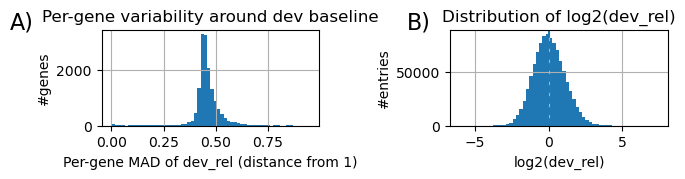

Median MAD: 0.4510771930217743
90th percentile MAD: 0.5193108916282654
Max MAD: 0.9482861757278442
Median: -0.0019126826
Mean: 0.036592238


In [40]:
fig, axs = plt.subplots(1, 2, figsize=(7,2))

# --- Panel A: per-gene MAD histogram ---
axs[0].hist(valid_mads, bins=60)
axs[0].set_xlabel("Per-gene MAD of dev_rel (distance from 1)")
axs[0].set_ylabel("#genes")
axs[0].set_title("Per-gene variability around dev baseline")
axs[0].text(-0.42, 1.2, "A)", transform=axs[0].transAxes,
           fontsize=16, va="top")
axs[0].grid(True)

# --- Panel B: log2(dev_rel) distribution ---
axs[1].hist(log_vals, bins=60)
axs[1].axvline(0.0, linestyle="--")
axs[1].set_xlabel("log2(dev_rel)")
axs[1].set_ylabel("#entries")
axs[1].set_title("Distribution of log2(dev_rel)")
axs[1].text(-0.2, 1.2, "B)", transform=axs[1].transAxes,
           fontsize=16, va="top")
axs[1].grid(True)

plt.tight_layout()              # run first
plt.subplots_adjust(wspace=0.6) # override afterwards
plt.show()


print("Median MAD:", np.median(valid_mads))
print("90th percentile MAD:", np.percentile(valid_mads, 90))
print("Max MAD:", np.max(valid_mads))

print("Median:", np.median(log_vals))
print("Mean:", np.mean(log_vals))

- So the “typical gene” deviates about ±50% from developmental baseline in detected cells.
- In B) 0 --> developmental baseline; the developmental baseline is behaving like a real central reference.

>Marker-level sanity checks

- To test interpretability at the gene level, we examined dev-relative values for **canonical markers**. 
- In the developmental atlas, hepatocyte markers (e.g., Alb), acinar enzymes (e.g. Prss1/Cpa1), ductal cytokeratins (e.g., Krt19, Krt8/18), and islet hormones (e.g., Ins, Gcg) should show dev-relative values near 1 in their expected lineages and near 0 elsewhere. 
- In PDAC, ductal-like clusters exhibited high dev-relative expression of ductal markers, whereas acinar-like or transdifferentiated clusters should show elevated dev-relative expression of acinar genes. 

These patterns confirm that the dev-relative scaling yields values that are consistent with known biology and remain interpretable as “fold-shifts” relative to typical developmental ON levels.

In [41]:
marker_genes = {
    "hepatocyte": ["Alb", "Apoa1", "Ttr"],
    "acinar": ["Prss1", "Cpa1", "Cela3a"],
    "ductal": ["Krt19", "Muc1", "Epcam", "Krt8", "Krt18"],
    "islet": ["Gcg", "Sst"],
    "biliary": ["Krt7", "Sox9"]
}

# Map gene symbol -> index for convenience
gene_to_idx = {gene: i for i, gene in enumerate(A_dev_mlm.var["symbol"])}

In [42]:
def plot_marker_violin(adata, rel_matrix, groupby, gene, labe, ylim=None, ax=None):
    """
    Plot per-group distribution of dev_rel/can_rel for a single gene.

    Parameters
    ----------
    adata : AnnData; Object with obs[groupby] defining the groups.
    rel_matrix : np.ndarray; 2D array (cells x genes) with relative expression values (e.g. dev_rel).
    groupby : str; Column in adata.obs to group by (e.g. "endo_category").
    gene : str; Gene name to plot.
    labe : int; 1 for dev_rel, 2 for can_rel
    ylim : tuple or None; y-axis limits (ymin, ymax). If None, use automatic limits.
    ax : matplotlib.axes.Axes or None; Axis to plot into. If None, uses current axis (plt.gca()).
    """
    if gene not in gene_to_idx:
        print(f"{gene} not in var_names")
        return

    if ax is None:
        import matplotlib.pyplot as plt
        ax = plt.gca()

    j = gene_to_idx[gene]
    vals = rel_matrix[:, j]

    df = pd.DataFrame({
        "rel_expr": vals,
        "group": adata.obs[groupby].values
    })

    # Drop zeros if you prefer to focus on ON distribution
    df_nz = df[df["rel_expr"] > 0]

    groups = sorted(df_nz["group"].unique())
    data = [df_nz[df_nz["group"] == g]["rel_expr"].values for g in groups]

    # Use tick_labels instead of deprecated labels
    bp = ax.boxplot(data, tick_labels=groups, showfliers=False)

    # Rotate x tick labels
    ax.set_xticklabels(groups, rotation=45, ha="right")

    # baseline
    ax.axhline(1.0, linestyle="--", linewidth=1)  
    
    if labe == 1:
        ax.set_ylabel(f"{gene} dev_rel")
        ax.set_title(f"{gene} dev_rel by {groupby}")
    else:
        ax.set_ylabel(f"{gene} can_rel")
        ax.set_title(f"{gene} can_rel by {groupby}")

    if ylim is not None:
        ax.set_ylim(ylim)

    return ax


**hepatocyte marker**

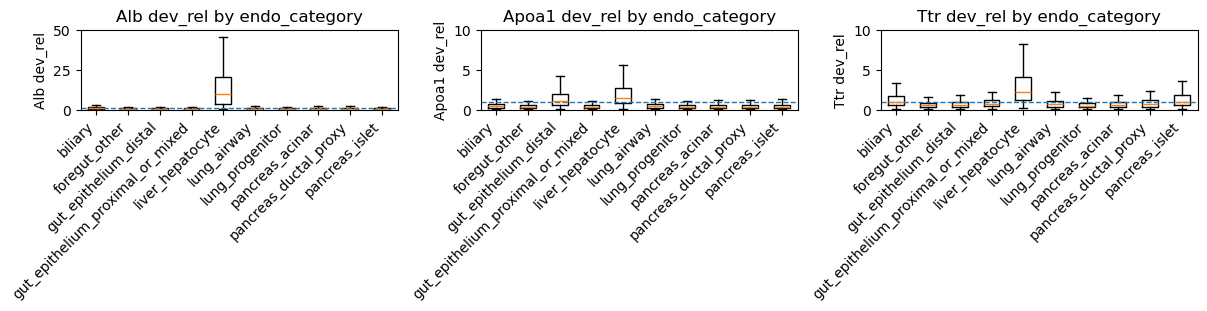

In [43]:
fig, axs = plt.subplots(1, 3, figsize=(12,3), constrained_layout=True)

genes = [marker_genes["hepatocyte"][0],marker_genes["hepatocyte"][1],marker_genes["hepatocyte"][2]]
ylims = [(0, 50), (0, 10), (0, 10)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_dev_mlm,dev_rel,groupby="endo_category",gene=gene,labe = 1,ylim=ylim,ax=ax)

plt.show()

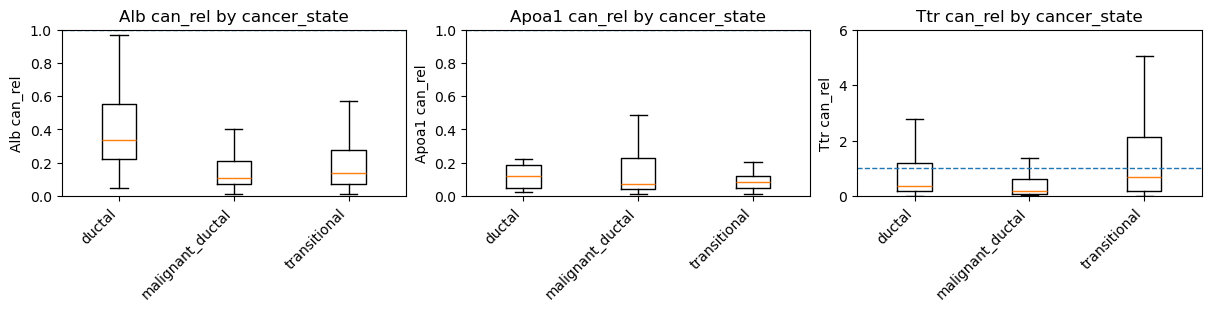

In [44]:
fig, axs = plt.subplots(1, 3, figsize=(12,3), constrained_layout=True)

genes = [marker_genes["hepatocyte"][0],marker_genes["hepatocyte"][1],marker_genes["hepatocyte"][2]]
ylims = [(0, 1),(0, 1),(0, 6)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_cancer_mlm,cancer_rel,groupby="cancer_state",gene=gene,labe = 2,ylim=ylim,ax=ax)

plt.show()

**acinar marker**

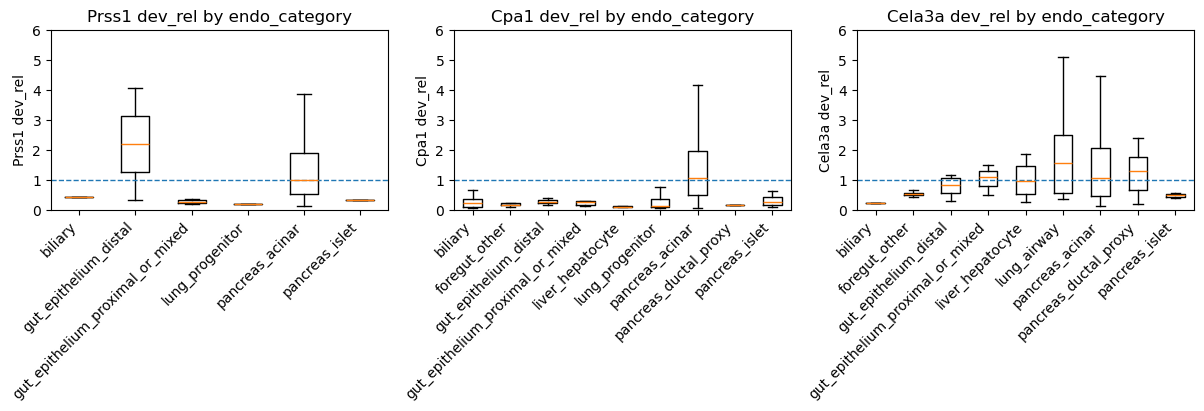

In [45]:
fig, axs = plt.subplots(1, 3, figsize=(12,4), constrained_layout=True)

genes = [marker_genes["acinar"][0],marker_genes["acinar"][1],marker_genes["acinar"][2]]
ylims = [(0, 6), (0, 6), (0, 6)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_dev_mlm,dev_rel,groupby="endo_category",gene=gene,labe=1,ylim=ylim,ax=ax)

plt.show()

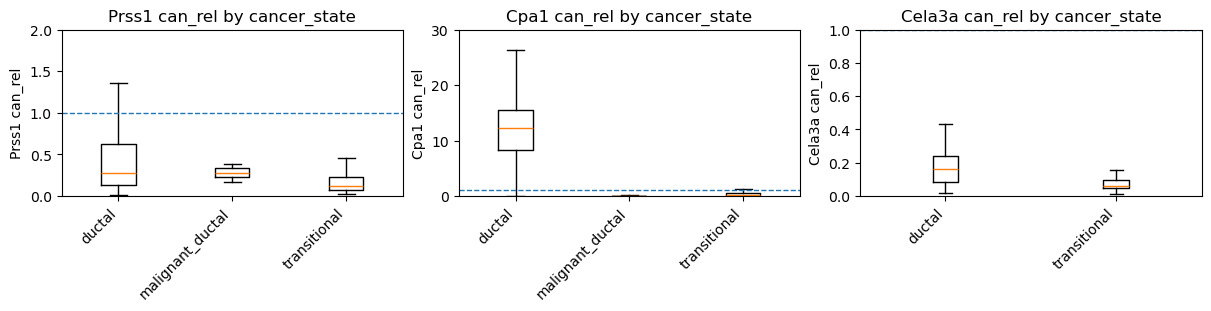

In [46]:
fig, axs = plt.subplots(1, 3, figsize=(12,3), constrained_layout=True)

genes = [marker_genes["acinar"][0],marker_genes["acinar"][1],marker_genes["acinar"][2]]
ylims = [(0, 2), (0, 30), (0, 1)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_cancer_mlm,cancer_rel,groupby="cancer_state",gene=gene,labe = 2,ylim=ylim,ax=ax)

plt.show()

**ductal marker**

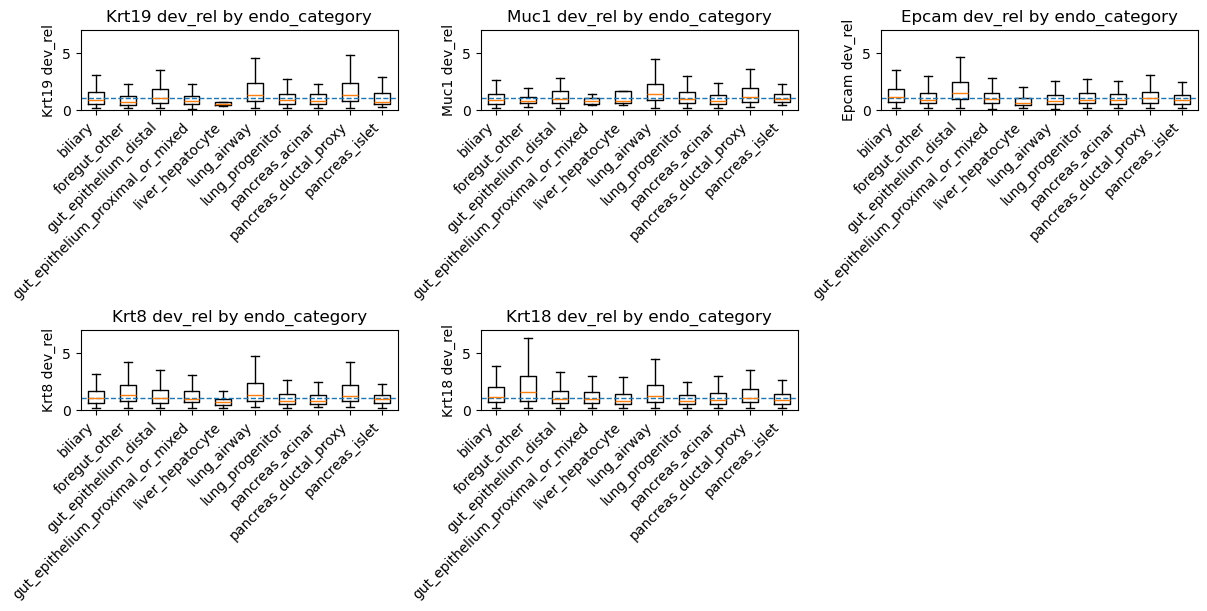

In [47]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)

# Flatten axes for easy looping
axs = axs.flatten()

genes = [marker_genes["ductal"][0],marker_genes["ductal"][1],marker_genes["ductal"][2],marker_genes["ductal"][3],marker_genes["ductal"][4]]

ylims = [(0, 7)] * 5

# Plot into the first 5 axes
for ax, gene, ylim in zip(axs[:5], genes, ylims):
    plot_marker_violin(A_dev_mlm,dev_rel,groupby="endo_category", gene=gene,labe=1,ylim=ylim,ax=ax)

# Hide the unused 6th subplot
axs[5].axis("off")

plt.show()


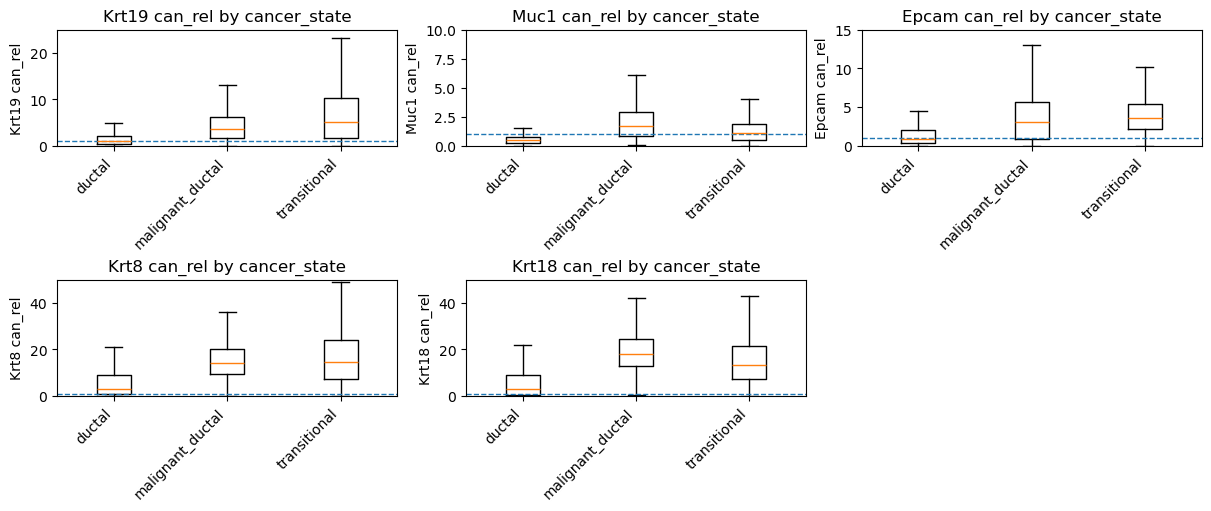

In [48]:
fig, axs = plt.subplots(2, 3, figsize=(12, 5), constrained_layout=True)

# Flatten axes for easy looping
axs = axs.flatten()

genes = [marker_genes["ductal"][0],marker_genes["ductal"][1],marker_genes["ductal"][2],marker_genes["ductal"][3],marker_genes["ductal"][4]]

ylims = [(0, 25), (0,10), (0,15),(0,50),(0,50)] 

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_cancer_mlm,cancer_rel,groupby="cancer_state",gene=gene,labe = 2,ylim=ylim,ax=ax)

# Hide the unused 6th subplot
axs[5].axis("off")
plt.show()

**islet marker**

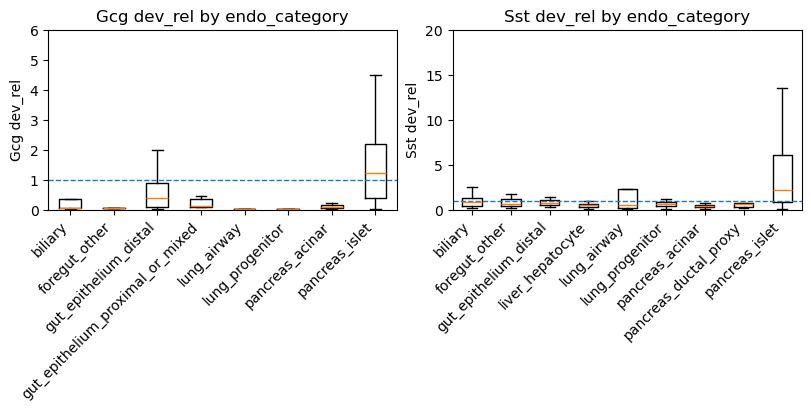

In [50]:
fig, axs = plt.subplots(1, 2, figsize=(8,4), constrained_layout=True)

genes = [marker_genes["islet"][0],marker_genes["islet"][1]]
ylims = [(0, 6), (0, 20)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_dev_mlm,dev_rel,groupby="endo_category",gene=gene,labe = 1,ylim=ylim,ax=ax)

plt.show()


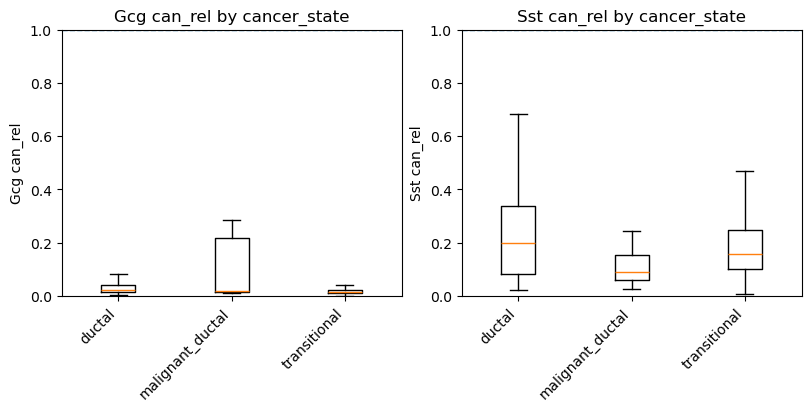

In [55]:
fig, axs = plt.subplots(1, 2, figsize=(8,4), constrained_layout=True)

genes = [marker_genes["islet"][0],marker_genes["islet"][1]]
ylims = [(0, 1), (0, 1)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_cancer_mlm,cancer_rel,groupby="cancer_state",gene=gene,labe = 2,ylim=ylim,ax=ax)

plt.show()

**biliary marker**

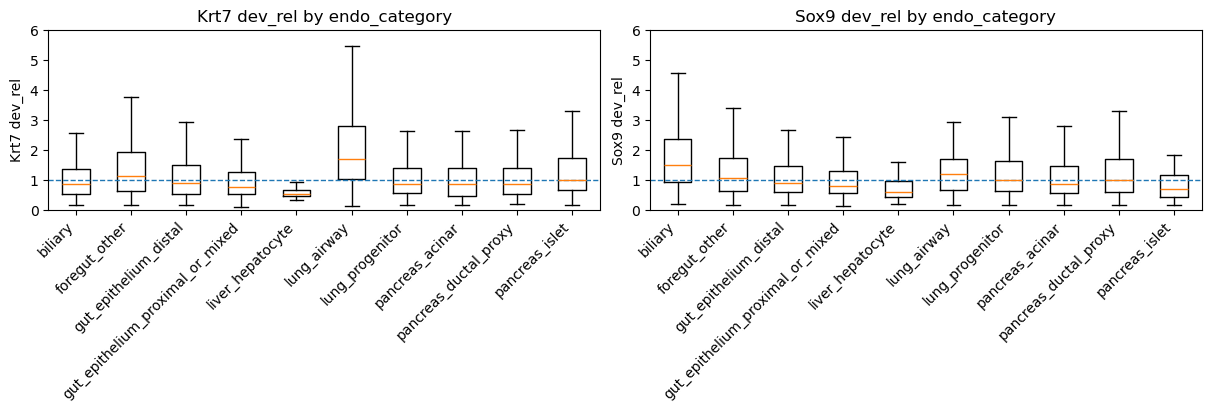

In [57]:
fig, axs = plt.subplots(1, 2, figsize=(12,4), constrained_layout=True)

genes = [marker_genes["biliary"][0],marker_genes["biliary"][1]]
ylims = [(0, 6), (0, 6)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_dev_mlm,dev_rel,groupby="endo_category",gene=gene,labe = 1,ylim=ylim,ax=ax)

plt.show()


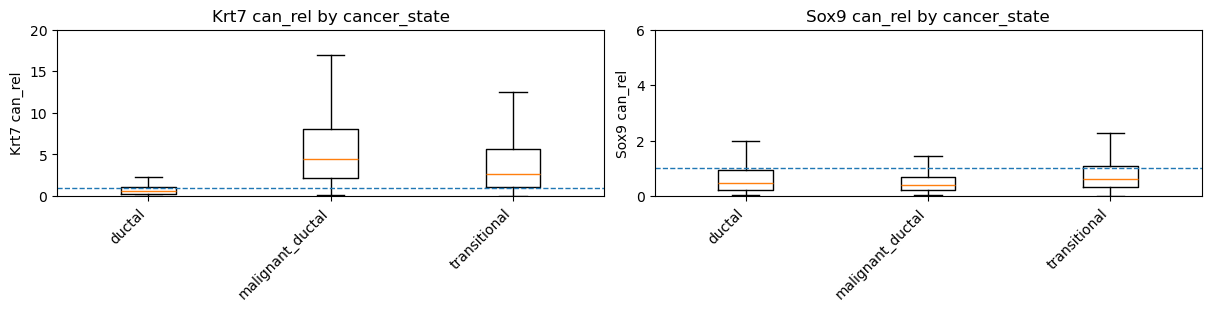

In [52]:
fig, axs = plt.subplots(1, 2, figsize=(12,3), constrained_layout=True)

genes = [marker_genes["biliary"][0],marker_genes["biliary"][1]]
ylims = [(0, 20), (0, 6)]

for ax, gene, ylim in zip(axs, genes, ylims):
    plot_marker_violin(A_cancer_mlm,cancer_rel,groupby="cancer_state",gene=gene,labe = 2,ylim=ylim,ax=ax)

plt.show()

#### Figure S4

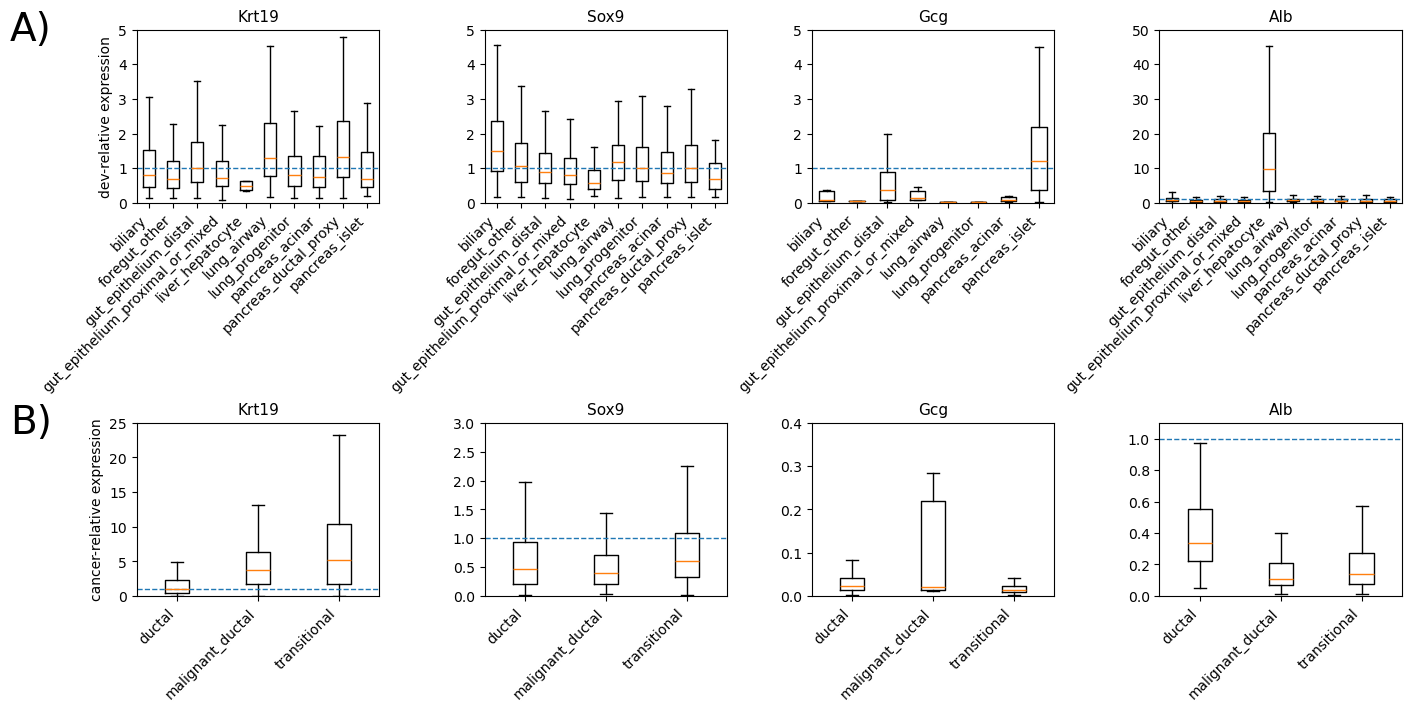

In [53]:
fig, axs = plt.subplots(2, 4,figsize=(14, 7),constrained_layout=True,sharex=False,sharey=False)

genes = ["Krt19", "Sox9", "Gcg", "Alb"]

# y-limits for dev_rel (top row)
ylims_dev = [(0, 5), (0, 5), (0, 5), (0, 50)]

# y-limits for cancer_rel (bottom row)
ylims_can = [(0, 25), (0, 3), (0, 0.4), (0, 1.1)]

# Row A: dev_rel
for j, (gene, ylim) in enumerate(zip(genes, ylims_dev)):
    ax = axs[0, j]
    plot_marker_violin(
        A_dev_mlm,
        dev_rel,
        groupby="endo_category",
        gene=gene,
        labe=1,
        ylim=ylim,
        ax=ax,
    )
    ax.set_title(gene, fontsize=11)
    if j == 0:
        ax.set_ylabel("dev-relative expression", fontsize=10)
    else:
        ax.set_ylabel("")

# Row B: cancer_rel
for j, (gene, ylim) in enumerate(zip(genes, ylims_can)):
    ax = axs[1, j]
    plot_marker_violin(
        A_cancer_mlm,
        cancer_rel,
        groupby="cancer_state",
        gene=gene,
        labe=1,
        ylim=ylim,
        ax=ax,
    )
    ax.set_title(gene, fontsize=11)
    if j == 0:
        ax.set_ylabel("cancer-relative expression", fontsize=10)
    else:
        ax.set_ylabel("")

# Row labels (A, B) on the left
axs[0, 0].text(-0.35, 1, "A)",transform=axs[0, 0].transAxes,fontsize=28,va="center",ha="right")

axs[1, 0].text(-0.35, 1, "B)",transform=axs[1, 0].transAxes,fontsize=28,va="center",ha="right")

# global title 
# fig.suptitle("Validation of dev-relative normalization and cancer-relative deviations",fontsize=12, y=1.02)

plt.show()


> Cross-dataset scaling in CPM space (X_dev_norm vs X_cancer_norm)

**Are dev and cancer comparable in CPM space?**  *Answer:* No, there is a large global shift

To evaluate whether developmental and PDAC datasets were comparable after per-cell library size normalization, we compared *per*-gene median expression in CPM space. For each gene, we computed the median of library-normalized counts across developmental and cancer cells, restricted to nonzero entries. *Per*-gene medians in PDAC closely tracked the developmental medians, with points scattered around the diagonal in CPM space. The distribution of log₂(median_cancer / median_dev) was centered near zero, indicating that library-size normalization yields comparable expression scales across datasets, and that large gene-level shifts reflect biology rather than global platform differences.


This checks whether your library-normalized counts are on roughly the same scale across datasets.

How to read it:
- Scatter around diagonal → CPM scales are comparable.
- Histogram of log₂ ratios centered near 0 → no massive global shift.


For the median gene, cancer CPM is ~4–5× lower than developmental CPM.
Why? Because:
- dev includes many tissues where each gene is strongly ON somewhere
- cancer is a single lineage
- CPM reflects fraction of total RNA, not biological relevance
- platform + composition effects dominate.

So the SCRIPT below (SCRIPT 1) correctly tells you:
- CPM space is not a shared coordinate system.
- This script is supposed to fail.
- That failure justifies your dev-relative normalization.

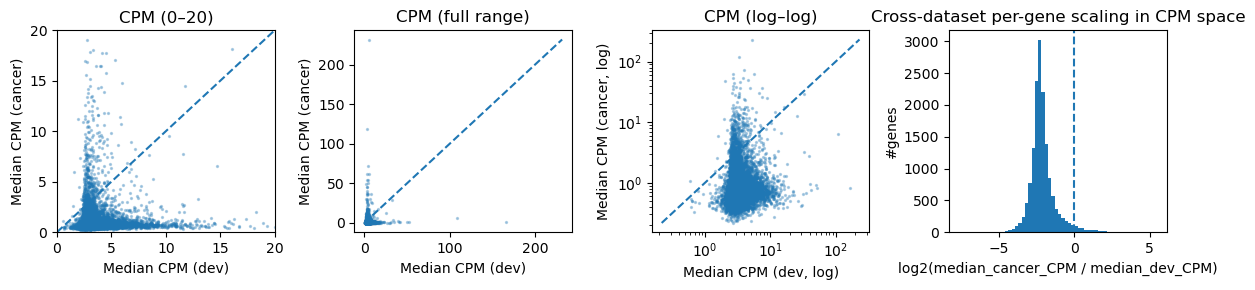

Median log2 ratio: -2.258025
Mean log2 ratio: -2.1214507


In [56]:
# SCRIPT 1: Cross-dataset comparison of per-gene median expression in CPM space
eps = 1e-8

def per_gene_nonzero_median_counts(X):
    n_genes = X.shape[1]
    med = np.zeros(n_genes, dtype=np.float32)
    for j in range(n_genes):
        col = X[:, j]
        nz = col[col > 0]
        med[j] = np.median(nz) if nz.size > 0 else np.nan
    return med

med_dev_cpm = per_gene_nonzero_median_counts(X_dev_norm)
med_can_cpm = per_gene_nonzero_median_counts(X_cancer_norm)

valid = ~np.isnan(med_dev_cpm) & ~np.isnan(med_can_cpm)
med_dev_cpm = med_dev_cpm[valid]
med_can_cpm = med_can_cpm[valid]

fig, axs = plt.subplots(1, 4, figsize=(12,3))

# Limited range subplot ---
axs[0].scatter(med_dev_cpm, med_can_cpm, s=2, alpha=0.3)
axs[0].set_xlim(0, 20)
axs[0].set_ylim(0, 20)

max_val = max(med_dev_cpm.max(), med_can_cpm.max())
axs[0].plot([0, max_val], [0, max_val], linestyle="--")

axs[0].set_xlabel("Median CPM (dev)")
axs[0].set_ylabel("Median CPM (cancer)")
axs[0].set_title("CPM (0–20)")


# Full-range subplot ---
axs[1].scatter(med_dev_cpm, med_can_cpm, s=2, alpha=0.3)

max_val2 = max(med_dev_cpm.max(), med_can_cpm.max())
axs[1].plot([0, max_val2], [0, max_val2], linestyle="--")

axs[1].set_xlabel("Median CPM (dev)")
axs[1].set_ylabel("Median CPM (cancer)")
axs[1].set_title("CPM (full range)")


# Log–log subplot ---
# Avoid log(0) issues by masking or adding a tiny epsilon
eps = 1e-6
x_log = med_dev_cpm + eps
y_log = med_can_cpm + eps

axs[2].scatter(x_log, y_log, s=2, alpha=0.3)
axs[2].set_xscale("log")
axs[2].set_yscale("log")

max_val3 = max(x_log.max(), y_log.max())
min_val3 = min(x_log.min(), y_log.min())
axs[2].plot([min_val3, max_val3], [min_val3, max_val3], linestyle="--")

axs[2].set_xlabel("Median CPM (dev, log)")
axs[2].set_ylabel("Median CPM (cancer, log)")
axs[2].set_title("CPM (log–log)")


# Distribution of log2 ratio ---
log2_ratio_cpm = np.log2((med_can_cpm + eps) / (med_dev_cpm + eps))

axs[3].hist(log2_ratio_cpm, bins=60)
axs[3].axvline(0.0, linestyle="--")
axs[3].set_xlabel("log2(median_cancer_CPM / median_dev_CPM)")
axs[3].set_ylabel("#genes")
axs[3].set_title("Cross-dataset per-gene scaling in CPM space")

plt.tight_layout()
plt.show()


print("Median log2 ratio:", np.median(log2_ratio_cpm))
print("Mean log2 ratio:", np.mean(log2_ratio_cpm))


On average, across all genes, median_cancer_CPM/median_dev_CPM ≈ 2^2.26 ≈ 0.21\
**So cancer CPM values are ~5-fold lower globally than developmental CPM values** (and the mean of –2.12 says nearly the same thing.)
- This is a strong global shift between the library-normalized cancer and developmental datasets.


**This is not biologically real.**
- PDAC cells do NOT globally express 5× fewer RNA molecules than embryonic epithelial cells.
- The total UMI per cell is already normalized out here (both are scaled to 1e4 CPM), so this is something else.

This is technology, not biology. Likely causes:
- A. Different sequencing chemistry / platform version
    - 10x v2 vs v3 → v3 captures far more UMIs and has different gene detection biases.
- B. Different cDNA quality / RNA degradation
    - Embryonic and tumor tissues behave very differently during dissociation.
- C. Different read depth / saturation
    - Even after scaling to 10k CPM, the per-gene distributions remain different because:
    - 10k CPM only normalizes total RNA captured
    - Not how many genes are detectable
    - Not the distribution of counts across genes
    - Not gene dropout curves
- D. Gene complexity differences
    - Some chemistries systematically under-quantify GC-rich transcripts, lncRNAs, mitochondrial genes, ribosomal genes, etc.
- E. Different preprocessing (cell filtering thresholds, RNA QC)
    - This is exactly the kind of thing CPM normalization cannot fix.

**What this implies for the normalization strategy**
- The dev-relative approach is the correct strategy, because:
    - If you used raw or CPM expression values, the 5× global shift would completely dominate distance metrics, embeddings, token rankings, and MLM training.
    - The model would learn chemistry differences, not biology.
    - The dev-relative scaling removes this global distortion by construction.
- This is precisely why we anchored cancer expression to the developmental nonzero median per gene — and not to cancer's own internal scale.
- In other words:
    - normalization was needed 
    — and this number proves why.

**The two datasets are on wildly different CPM scales, even after library normalization.**

> cancer_rel per-gene medians

Given a common developmental reference, which parts of the grammar does cancer actually deploy?\
In other words,
- Across genes, how much does cancer use each gene relative to its own developmental ON level? This is not a scaling test. It is a **biological usage** test.

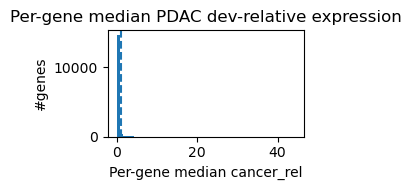

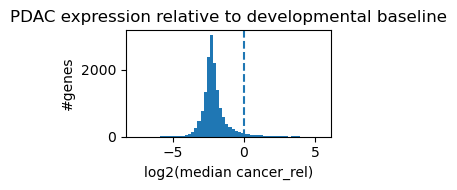

Median cancer_rel median: 0.20905775
Median log2(median cancer_rel): -2.2580197


In [57]:
# SCRIPT 2: Analyze cancer relative expression
def per_gene_nonzero_median_rel(rel_matrix, nonzero_baseline_mask):
    n_genes = rel_matrix.shape[1]
    med = np.zeros(n_genes, dtype=np.float32)
    for j in range(n_genes):
        if not nonzero_baseline_mask[j]:
            med[j] = np.nan
            continue
        col = rel_matrix[:, j]
        nz = col[col > 0]
        med[j] = np.median(nz) if nz.size > 0 else np.nan
    return med

nonzero_baseline = ~zero_baseline

med_can_rel = per_gene_nonzero_median_rel(cancer_rel, nonzero_baseline)
med_can_rel = med_can_rel[~np.isnan(med_can_rel)]

# Histogram of cancer medians in dev-relative units
plt.figure(figsize=(3,2))
plt.hist(med_can_rel, bins=60)
plt.axvline(1.0, linestyle="--")
plt.xlabel("Per-gene median cancer_rel")
plt.ylabel("#genes")
plt.title("Per-gene median PDAC dev-relative expression")
plt.tight_layout()
plt.show()

log2_med_can_rel = np.log2(med_can_rel + eps)
plt.figure(figsize=(3,2))
plt.hist(log2_med_can_rel, bins=60)
plt.axvline(0.0, linestyle="--")
plt.xlabel("log2(median cancer_rel)")
plt.ylabel("#genes")
plt.title("PDAC expression relative to developmental baseline")
plt.tight_layout()
plt.show()

print("Median cancer_rel median:", np.median(med_can_rel))
print("Median log2(median cancer_rel):", np.median(log2_med_can_rel))


If the distribution of median cancer_rel is centered around 1 → on average, PDAC uses genes at about the typical developmental ON level.
If it’s shifted up → global upregulation relative to dev baseline.
You can also look at specific gene sets (cell cycle, KRAS targets, EMT) to show they are systematically >1.

| Aspect                  | SCRIPT 1                 | SCRIPT 2                                |
| ----------------------- | ------------------------ | --------------------------------------- |
| Space                   | CPM                      | dev-relative                            |
| Denominator             | dev CPM (implicit)       | dev CPM (explicit)                      |
| Question                | “Are scales comparable?” | “How much development does cancer use?” |
| Expected median         | ~0                       | **≪ 0**                                 |
| Interpretation of −2.25 | Scaling failure          | Lineage restriction                     |


### Summary:
- SCRIPT 1 shows CPM is not a shared coordinate system; 
- SCRIPT 2 shows that once a shared coordinate system is imposed, cancer occupies only a restricted, biologically meaningful subset of developmental expression.

purity scaling sanity check

In [58]:
mask_used = med_can_rel > 0.5   # or >1
print("Median log2(med_can_rel | used genes):",
      np.median(np.log2(med_can_rel[mask_used] + eps)))


Median log2(med_can_rel | used genes): -0.3009883


In [63]:
for thr in [0.25, 0.5, 1.0, 2.0]:
    m = med_can_rel > thr
    val = np.median(np.log2(med_can_rel[m] + eps))
    n = m.sum()
    print(f"thr>{thr:>4}: n_genes={n:>5}  median log2={val: .3f}  median fold={2**val: .2f}")


thr>0.25: n_genes= 4823  median log2=-1.560  median fold= 0.34
thr> 0.5: n_genes= 1233  median log2=-0.301  median fold= 0.81
thr> 1.0: n_genes=  459  median log2= 0.712  median fold= 1.64
thr> 2.0: n_genes=  178  median log2= 1.608  median fold= 3.05


In [ ]:
def per_gene_nonzero_median_counts(X):
    """Per-gene median over nonzero entries across cells."""
    X = np.asarray(X, dtype=np.float32)
    n_genes = X.shape[1]
    med = np.full(n_genes, np.nan, dtype=np.float32)
    for j in range(n_genes):
        col = X[:, j]
        nz = col[col > 0]
        if nz.size > 0:
            med[j] = np.median(nz)
    return med

def per_gene_nonzero_median_rel(rel_matrix, nonzero_baseline_mask):
    """Per-gene median over nonzero entries across cancer cells, restricted to genes with dev baseline > 0."""
    X = np.asarray(rel_matrix, dtype=np.float32)
    n_genes = X.shape[1]
    med = np.full(n_genes, np.nan, dtype=np.float32)
    for j in range(n_genes):
        if not nonzero_baseline_mask[j]:
            continue
        col = X[:, j]
        nz = col[col > 0]
        if nz.size > 0:
            med[j] = np.median(nz)
    return med


#### Figure S5

In [61]:
# RECOMPUTING ALL FOR FIGURE
# Panel A: CPM-space ratios
# -----------------------------
med_dev_cpm = per_gene_nonzero_median_counts(X_dev_norm)
med_can_cpm = per_gene_nonzero_median_counts(X_cancer_norm)

valid_cpm = np.isfinite(med_dev_cpm) & np.isfinite(med_can_cpm)
log2_ratio_cpm = np.log2((med_can_cpm[valid_cpm] + eps) / (med_dev_cpm[valid_cpm] + eps))

med_log2_ratio_cpm = np.median(log2_ratio_cpm)

# Panel B: dev-relative medians in cancer
# -----------------------------
nonzero_baseline = ~zero_baseline
med_can_rel = per_gene_nonzero_median_rel(cancer_rel, nonzero_baseline)
med_can_rel = med_can_rel[np.isfinite(med_can_rel)]

log2_med_can_rel = np.log2(med_can_rel + eps)
med_log2_all = np.median(log2_med_can_rel)

# "used genes" threshold (adjust if desired)
thr = 0.5
mask_used = med_can_rel > thr
log2_used = np.log2(med_can_rel[mask_used] + eps)
med_log2_used = np.median(log2_used)

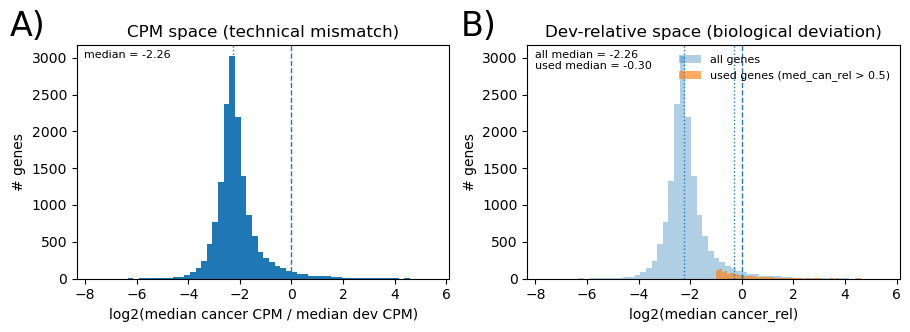

Panel A: median log2 CPM ratio = -2.2580249309539795
Panel B: median log2(med_can_rel) all genes = -2.2580196857452393
Panel B: median log2(med_can_rel) used genes (>0.5) = -0.3009882867336273


In [62]:

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)


# --- Panel A ---
ax = axes[0]
ax.hist(log2_ratio_cpm, bins=60)
ax.axvline(0.0, linestyle="--", linewidth=1)
ax.axvline(med_log2_ratio_cpm, linestyle=":", linewidth=1)

ax.text(-0.18, 1.15, "A)",transform=ax.transAxes,fontsize=24,va="top",ha="left")

ax.set_xlabel("log2(median cancer CPM / median dev CPM)")
ax.set_ylabel("# genes")
ax.set_title("CPM space (technical mismatch)")
ax.text(
    0.02, 0.98,
    f"median = {med_log2_ratio_cpm:.2f}",
    transform=ax.transAxes,
    va="top", ha="left", fontsize=8
)

# --- Panel B ---
ax = axes[1]
ax.hist(log2_med_can_rel, bins=60, alpha=0.35, label="all genes")
ax.hist(log2_used, bins=60, alpha=0.65, label=f"used genes (med_can_rel > {thr})")

ax.axvline(0.0, linestyle="--", linewidth=1)
ax.axvline(med_log2_all, linestyle=":", linewidth=1)
ax.axvline(med_log2_used, linestyle=":", linewidth=1)

ax.text(-0.18, 1.15, "B)",transform=ax.transAxes,fontsize=24,va="top",ha="left")

ax.set_xlabel("log2(median cancer_rel)")
ax.set_ylabel("# genes")
ax.set_title("Dev-relative space (biological deviation)")
ax.legend(frameon=False, fontsize=8)

ax.text(
    0.02, 0.98,
    f"all median = {med_log2_all:.2f}\nused median = {med_log2_used:.2f}",
    transform=ax.transAxes,
    va="top", ha="left", fontsize=8
)

plt.show()

# -----------------------------
# Print the key medians for the caption / text
# -----------------------------
print("Panel A: median log2 CPM ratio =", float(med_log2_ratio_cpm))
print("Panel B: median log2(med_can_rel) all genes =", float(med_log2_all))
print(f"Panel B: median log2(med_can_rel) used genes (>{thr}) =", float(med_log2_used))


> Interpreting the huge CPM platform effect with the papers in hand


You’re seeing ~4–7× higher CPM medians for housekeeping genes in PDAC compared to development (log₂ ≈ 2–2.7). That’s not subtle; it’s a genuine platform + biology mixture. Here’s what the papers say and how it fits.

-   Different technologies and molecules
Developmental atlas (Qiu et al. Nature 2024)
Uses sci-RNA-seq3, an optimized single-nucleus combinatorial indexing method.
Nuclei from flash-frozen whole embryos are profiled; median 2,545 UMIs per nucleus.
Nuclei, not whole cells → under-representation of cytoplasmic mRNAs, different capture bias (length, intronic content, etc.), generally lower dynamic range for strongly cytoplasmic genes (like many classical housekeeping genes).
PDAC study (Burdziak et al. Science 2023)
FACS-sorted whole epithelial or immune cells, processed using 10x Genomics 3' v2 chemistry.
10x v2 whole-cell scRNA-seq generally captures more UMIs and more cytoplasmic, high-abundance transcripts per cell than sci-RNA-seq3 nuclei (even after per-cell library normalization).
So even after scaling each cell to the same total counts (CPM), the composition of captured molecules per cell is different:
sci-RNA-seq3 nuclei: more intronic, more long, nuclear RNAs → housekeeping mRNAs are a smaller share of the total library.
10x 3' v2 whole cells: high cytoplasmic mRNA load, including Actb/Gapdh/Tuba1a, which become a larger fraction of the CPM budget.
That alone can easily give you a few-fold CPM shift for ubiquitous genes.

-   Tissue and cell-state composition
Developmental atlas = whole embryo, all tissues, all lineages, from E8 to birth.
PDAC dataset = sorted pancreatic epithelial cells along the damage–metaplasia–neoplasia axis.
Even with nonzero medians, the typical intensity of “ON” can differ:
Embryonic cells at many stages are small, rapidly dividing, and have a lot of regulatory, low-abundance transcripts relative to structural ones.
PDAC epithelial cells are hypertrophic, metabolically active, with boosted cytoskeletal and metabolic programs (including Actb, Gapdh).
So in CPM terms, housekeeping genes take a bigger slice of the transcriptome in PDAC than in the average embryonic cell. That’s a biological difference plus a technical one.

-   Pipeline differences
The two studies also use different normalization/back-end pipelines:
Qiu et al. process sci-RNA-seq3 counts with their own pipeline and downstream Scanpy analysis.
Burdziak et al. process 10x counts with SEQC, filter, then log library-size normalized (scran-like) before downstream analyses.
Your CPM normalization re-imposes a uniform 10k library across both, but it can’t undo everything:
If platform A tends to “spread” counts across many lowly expressed genes (nuclear, developmental dataset) and platform B tends to concentrate reads on a smaller subset of highly expressed cytoplasmic genes (10x PDAC), the relative CPM for Actb/Gapdh will be higher in B even after rescaling.

-   Why dev-relative normalization fixes it
Given all that, the ~4–7× CPM shift in housekeeping genes is not interpretable as biology alone. It’s a mashup of:
        nuclei vs whole-cell capture,
        sci-RNA-seq3 vs 10x chemistry,
        developmental vs adult PDAC tissue states,
        and different processing pipelines.

Your dev-relative normalization does two critical things:
-   Anchors every gene to its own developmental “ON” level (median nonzero developmental expression).
        In dev data, that collapses medians to 1.
        In PDAC, cancer_rel tells you how far off that developmental ON level you are.

-   Removes cross-platform scalar differences:
        If a platform globally boosts housekeeping genes 4–7×, that multiplies both numerator and denominator for those genes, which largely cancels in the ratio.
        That’s exactly what you see: Actb / Gapdh / Tuba1a cluster around log₂ dev_rel ≈ 0 in PDAC space instead of 2–3.

The new dev-relative scatter shows:
        Non-pancreas developmental markers (lung, thyroid, stomach, islet, etc.) far below zero → not used by PDAC.
        Pancreas markers separating into up (Krt8/18/19) and down (Ptf1a/Pdx1).
        Housekeeping genes sitting near zero → the massive CPM shift is gone and no longer misleads the model.

So the huge platform effect in CPM is expected from sci-RNA-seq3 nuclei vs 10x whole-cell PDAC and shouldn’t be interpreted biologically. Your dev-relative normalization is doing the right thing: it strips out these platform-specific distortions and leaves you with interpretable developmental deviations.

The 'next' step could be:
**Quantify explicitly how much of the CPM shift is explained by gene length and nuclear vs cytoplasmic bias (e.g. compare dev_rel shifts across short vs long genes). That would make a nice supplementary figure to convince picky reviewers that you’ve really tamed the platform mess.**

(*some extract analyses not yet included in the Supplement are in Bert_withsomeextras.ipynb*)

## TRAIN

(a) Model config
- vocab_size = 4 + n_genes + 2 (the +2 are the domain tokens).
- max_position_embeddings ≥ TOP_K + 3 (DOM + CLS + K + SEP) + a little safety margin.

In [63]:
seq_len = TOP_K + 3  # DOM + CLS + K genes + SEP

config = BertConfig(
    vocab_size=vocab_size,
    hidden_size=256,
    num_hidden_layers=6,
    num_attention_heads=8,
    intermediate_size=512,
    max_position_embeddings=seq_len + 2,  # small cushion
    pad_token_id=PAD_ID
)

In [64]:
model = BertForMaskedLM(config)

(b) Dataset wrapper

It wraps two arrays:
-   tokens: your BERT input sequences
-   attn: attention masks

into a PyTorch-compatible dataset object. This allows batching, shuffling, GPU transfer, integration with HuggingFace Trainer
masked language modeling collators. None of those work without implementing something like this.

In [65]:
class TokenDataset(Dataset):
    def __init__(self, tokens, attn):
        self.tokens = torch.as_tensor(tokens, dtype=torch.long)
        self.attn   = torch.as_tensor(attn,   dtype=torch.long)
    def __len__(self):
        return self.tokens.shape[0]
    def __getitem__(self, i):
        return {"input_ids": self.tokens[i], "attention_mask": self.attn[i]}

In [66]:
ds_train = TokenDataset(X_tokens, X_attn)

(c) Collator

**What does the collator do?** Every time the DataLoader prepares a batch, the collator:
- Takes raw "input_ids" and "attention_mask" from the dataset
- Randomly masks some of the gene tokens
- Produces:
    - "input_ids" (with MASK tokens or random replacements)
    - "labels" (what the model is supposed to predict)
    - "attention_mask" (carry over unchanged)

This is exactly how BERT learns to predict missing words; your model learns to predict missing genes.

In [72]:
SPECIAL_IDS = {PAD_ID, CLS_ID, SEP_ID, MASK_ID, DEV_DOM_ID, CANCER_DOM_ID}

@dataclass
class SimpleMLMCollator:
    mlm_probability: float = 0.15 # probability of masking each token

    def __call__(self, batch):
        # Build the batch tensors
        input_ids     = torch.stack([b["input_ids"] for b in batch], dim=0)  # (B, L)
        attention_mask= torch.stack([b["attention_mask"] for b in batch], 0)

        labels = input_ids.clone()
        # build maskable positions: not special, not pad
        maskable = torch.ones_like(input_ids, dtype=torch.bool)
        for sid in SPECIAL_IDS:
            maskable &= (input_ids != sid)

        # sample which tokens to mask
        prob = torch.full(input_ids.shape, self.mlm_probability, dtype=torch.float32)
        sampled = (torch.bernoulli(prob).bool()) & maskable

        # 80% -> [MASK], 10% -> random token, 10% -> keep
        replace_mask = sampled & (torch.rand_like(input_ids, dtype=torch.float32) < 0.8)
        random_mask  = sampled & (~replace_mask) & (torch.rand_like(input_ids, dtype=torch.float32) < 0.5)

        input_ids[replace_mask] = MASK_ID
        # random tokens from gene+special vocab (you may prefer gene-only: ids >= 4)
        rand_ids = torch.randint(low=4, high=vocab_size, size=input_ids.shape, dtype=torch.long)
        input_ids[random_mask] = rand_ids[random_mask]

        # ignore loss on non-sampled positions
        labels[~sampled] = -100

        return {"input_ids": input_ids,
                "attention_mask": attention_mask,
                "labels": labels}


(d) Train with Trainer

In [67]:
# free any stray allocations before starting
gc.collect()
torch.cuda.empty_cache()

OUTDIR = os.path.join(commonpath,"out/bert_dev_cancer_last_norm_3/")
os.makedirs(OUTDIR, exist_ok=True)


In [73]:
# ----- Training arguments tuned for 8 GB GPU -----
# Train my dev+cancer BERT for 10 passes over the data, 
# using a realistic batch size for an 8 GB GPU, with careful memory use 
# and a standard transformer training schedule (warmup, linear decay, 
# gradient clipping, fp16). 
# Mask 15% of gene tokens in each batch and teach the model to predict them.

args = TrainingArguments(
    output_dir=OUTDIR,
    overwrite_output_dir=True,              # this allows training to overwrite 

    # smaller micro-batch + gradient accumulation to simulate larger batch
    per_device_train_batch_size=8,          # each training step only sees 8 cells at a time on the GPU (memory usage low)
    # you don’t want such a tiny batch forever, because that makes training very noisy.
    # So: 1/do 4 mini-steps, each with batch size 8, 2/accumulate their gradients, 3/only then update the model once
    gradient_accumulation_steps=4,          # 8 × 4 = effective batch of 32

    # How many times you go through the entire training dataset.
    # More epochs → more training → more chance to learn patterns, but also more risk of overfitting if you go too far.
    num_train_epochs=10,
    # typical value for MLM on medium models; a bit aggressive, which is why warmup and clipping are also used.
    learning_rate=5e-4,
    # AdamW weight decay to regularize and prevent overfitting
    weight_decay=0.01,
    # for the first 6% of training steps, the learning rate linearly ramps up from 0 → full value (0.0005).
    # After that, it follows the main schedule. Training smoother and less likely to get stuck early on.
    warmup_ratio=0.06,
    # After warmup, the learning rate slowly decreases in a straight line toward 0 as training progresses
    lr_scheduler_type="linear",
    # clip  gradients to max norm of 1.0 to prevent exploding gradients
    max_grad_norm=1.0,

    # Saves around 50% GPU memory. Speeds up computation on GPUs designed for it.
    # Slightly more numerically fragile than bf16, but usually fine with clipping + warmup.
    # This is how you squeeze BERT onto an 8 GB card.
    fp16=True,                              

    # simply throws away that last partial batch -if training sample is not divisible by batch- as it can cause instability
    dataloader_drop_last=True,

    logging_steps=50,       # log every 50 steps
    save_total_limit=2,     # only keep last 2 checkpoints to save disk space
    report_to="none",       # disable WandB or other loggers
)

# it’s a “be nice to the GPU” switch.
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"


In [74]:
# ----- Trainer -----
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_train,
    data_collator=SimpleMLMCollator(mlm_probability=0.15)
)

**training!**

In [43]:
trainer.train()

Step,Training Loss
50,9.657200
100,9.484900
150,9.143800
200,8.817800
250,8.578900
300,8.422600
350,8.389300
400,8.133000
450,8.058500
500,7.800000


TrainOutput(global_step=19660, training_loss=5.413279724897228, metrics={'train_runtime': 3236.6673, 'train_samples_per_second': 194.308, 'train_steps_per_second': 6.074, 'total_flos': 1603914476256960.0, 'train_loss': 5.413279724897228, 'epoch': 10.0})

#### AFTER THE MODEL LEARNED

`save the model`

What this writes to save_dir:
- config.json
- pytorch_model.bin (or model.safetensors)
- training_args.bin

Important: This saves model weights + architecture config, but **not** your custom vocabulary metadata.

In [ ]:
model_dir = os.path.join(commonpath,"models/bert_dev_learned/") # former model 8
# 1) Save the final model weights + config
trainer.save_model(model_dir)   

meta = {"gene2id": gene2id,"PAD_ID": PAD_ID,"CLS_ID": CLS_ID,"SEP_ID": SEP_ID,"MASK_ID": MASK_ID,
        "DEV_DOM_ID": DEV_DOM_ID,"CANCER_DOM_ID": CANCER_DOM_ID,"vocab_size": vocab_size}

with open(os.path.join(model_dir, "vocab_meta.json"), "w") as f:
    json.dump(meta, f)

# ..
np.save(os.path.join(model_dir, "X_tokens.npy"), X_tokens)
np.save(os.path.join(model_dir, "X_attn.npy"), X_attn)
np.save(os.path.join(model_dir, "domain.npy"), domain)


# ????? WHERE IS THIS ?????
# 3) (Optional) Save domain labels or anything else you need later. 
#np.save(os.path.join(model_dir, "domain_labels.npy"), domain_eval)


`how good the model is`

In [ ]:
log = pd.DataFrame(trainer.state.log_history)
print(log.tail(10))

`load model`

(*one can restart the kernel here and import the initial modules*)

In [ ]:
model_dir = os.path.join(commonpath,"models/bert_dev_learned/") # former model 8

In [8]:
# loads a pretrained BERT model for masked language modeling
# config.json defines the model architecture and settings
# model.safetensors contains the trained weights
model = BertForMaskedLM.from_pretrained(model_dir)

meta_path = os.path.join(model_dir, "vocab_meta.json")
with open(meta_path) as f:
    meta = json.load(f)

# Meta is a dictionary with the following keys
print('keys of meta dictionary -> ',meta.keys())

required = ["gene2id","PAD_ID","CLS_ID","SEP_ID","MASK_ID","DEV_DOM_ID","CANCER_DOM_ID","vocab_size"]
missing = [k for k in required if k not in meta]
assert not missing, f"vocab_meta.json missing keys: {missing}"

# unpacking the dictionary into variables.
gene2id       = meta["gene2id"]
PAD_ID        = meta["PAD_ID"]
CLS_ID        = meta["CLS_ID"]
SEP_ID        = meta["SEP_ID"]
MASK_ID       = meta["MASK_ID"]
DEV_DOM_ID    = meta["DEV_DOM_ID"]
CANCER_DOM_ID = meta["CANCER_DOM_ID"]
vocab_size    = meta["vocab_size"]

# Sanity checks (fail fast)
assert model.config.vocab_size == vocab_size, (
    f"Model vocab_size ({model.config.vocab_size}) != meta vocab_size ({vocab_size}). "
    "You likely loaded mismatched checkpoint + vocab."
)

# Ensure special IDs are in range and distinct (no two special tokens share the same ID)
specials = [PAD_ID, CLS_ID, SEP_ID, MASK_ID, DEV_DOM_ID, CANCER_DOM_ID]
assert len(set(specials)) == len(specials), "Some special token IDs collide."
assert all(0 <= x < vocab_size for x in specials), "A special token ID is out of vocab range."

keys of meta dictionary ->  dict_keys(['gene2id', 'PAD_ID', 'CLS_ID', 'SEP_ID', 'MASK_ID', 'DEV_DOM_ID', 'CANCER_DOM_ID', 'vocab_size'])


In [ ]:
X_tokens_eval = np.load(os.path.join(model_dir, "X_tokens.npy"))
X_attn_eval   = np.load(os.path.join(model_dir, "X_attn.npy"))
domain_eval   = np.load(os.path.join(model_dir, "domain.npy"))

**CLS UMAP dev vs cancer**

Cosine between dev and cancer CLS means: 0.4594068084945449


/home/jfpoyatos/miniconda3/envs/plasticity/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


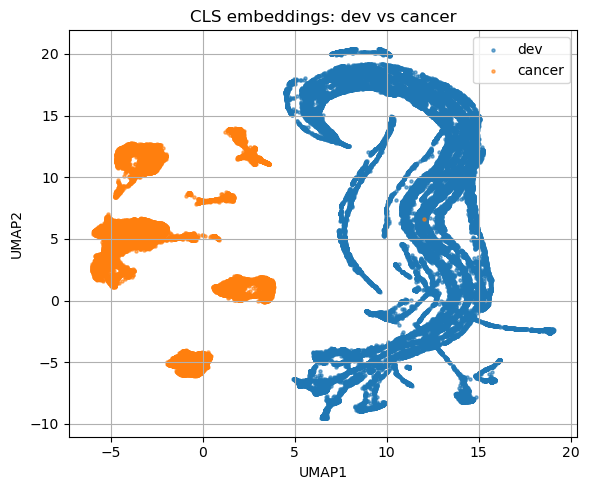

In [9]:
# Define cls_embeddings ----------
@torch.no_grad()
def cls_embeddings(model, Xt, At, batch_size=16):
    """
    Compute CLS embeddings for a set of tokenized cells.

    Xt: numpy array of shape (N, L) with token IDs
    At: numpy array of shape (N, L) with attention masks
    batch_size: how many cells to process at once (for memory reasons)

    Returns:
      CLS: numpy array of shape (N, H)
           where H = hidden size of the BERT model.
           Each row is the CLS embedding for one cell.
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()

    embs = []

    N = Xt.shape[0]
    for i in range(0, N, batch_size):
        # Take a minibatch of cells
        x_batch = Xt[i:i+batch_size]
        a_batch = At[i:i+batch_size]

        # Convert to torch tensors on the right device
        x = torch.as_tensor(x_batch, dtype=torch.long, device=device)  # (B, L)
        a = torch.as_tensor(a_batch, dtype=torch.long, device=device)  # (B, L)

        # Run only the BERT encoder
        out = model.bert(
            input_ids=x,
            attention_mask=a,
            output_hidden_states=False,
            return_dict=True
        )

        # out.last_hidden_state: (B, L, H)
        # Your sequence is [DOM], [CLS], genes..., [SEP],
        # so CLS is at position index 1.
        cls_batch = out.last_hidden_state[:, 1, :]   # (B, H)

        # Move to CPU and store
        embs.append(cls_batch.cpu())

    # Concatenate all batches -> (N, H)
    CLS = torch.cat(embs, dim=0).numpy()
    return CLS

# Compute CLS embeddings for eval set ----------

CLS = cls_embeddings(model, X_tokens_eval, X_attn_eval, batch_size=16)  # (N, H)

# domain_eval: 0 = development, 1 = cancer
is_dev = (domain_eval == 0)
is_can = (domain_eval == 1)

# Compute dev/cancer centroids and cosine between them ----------

E_dev_mean = CLS[is_dev].mean(axis=0)
E_can_mean = CLS[is_can].mean(axis=0)

def cos(u, v):
    return float(np.dot(u, v) / (norm(u) * norm(v) + 1e-12))

print("Cosine between dev and cancer CLS means:", cos(E_dev_mean, E_can_mean))

# ---------- 4. UMAP to 2D and plot ----------

umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

X2 = umap_model.fit_transform(CLS)  # (N, 2)

plt.figure(figsize=(6, 5))
plt.scatter(X2[is_dev, 0], X2[is_dev, 1], s=5, alpha=0.6, label="dev")
plt.scatter(X2[is_can, 0], X2[is_can, 1], s=5, alpha=0.6, label="cancer")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("CLS embeddings: dev vs cancer")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
